---
title: "Daten putzen: Ausreißer, fehlende Werte, Datentypen"
short_title: "Daten putzen"
description: "Der größte Teil der täglichen Arbeit: Ausreißer erkennen, fehlende Werte behandeln, Datentypen und Encoding reparieren, Text mit regulären Ausdrücken zerlegen, Datum und Zeitzonen."
---

[Vorlesungsaufzeichnung Daten putzen](https://media.hhu.de/channel/video/data-science-vl-14-daten-putzen-2025/94dcb9e6c116ae198e227db3cd5788a9/167)

Im ersten Kapitel stand, dass der größte Teil der täglichen Arbeit von Data Scientists nicht die Modellierung ist, sondern Datenbeschaffung, Datenbereinigung und Kommunikation. Dieses Kapitel ist der Bereinigung gewidmet, dem "Daten schrubben": Ausreißer erkennen, fehlende Werte behandeln, Datentypen reparieren, Text mit regulären Ausdrücken zerlegen, Datum und Uhrzeit richtig lesen. Nichts davon ist mathematisch tief, aber alles davon entscheidet darüber, ob die Modelle der folgenden Kapitel etwas taugen.

:::{admonition} Grundsatz
Jedes Putzen verfälscht die Daten. Wer einen Ausreißer entfernt, einen fehlenden Wert einsetzt oder einen String normalisiert, ändert die Stichprobe. Das ist in Ordnung, solange drei Regeln gelten:

1. **Protokollieren.** Jede Änderung ist reproduzierbar im Code festgehalten, am besten mit einer Spalte, die markiert, welche Werte geändert wurden. Niemals von Hand in der CSV-Datei oder in Excel editieren.
2. **Hinterher hinschauen.** Nach jedem Schritt die Verteilung wieder plotten und prüfen, ob sie noch plausibel aussieht.
3. **An der Zielmetrik messen.** Ob man fehlende Werte auffüllt oder die Zeilen wegwirft, entscheidet nicht das Bauchgefühl, sondern die Kennzahl, mit der man später den Erfolg der ganzen Pipeline misst. Wenn man es nicht messen kann, wählt man die Variante, die die Daten am wenigsten verändert.
:::

Die Beispieldaten sind Tageswerte der Wetterstation Düsseldorf aus dem [Open-Data-Portal des Deutschen Wetterdienstes](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/), dazu am Ende der Titanic-Datensatz für die Textverarbeitung.

## Daten laden und erster Blick

Der DWD liefert je Station ein ZIP-Archiv mit einer Datendatei und mehreren Metadatendateien. Fehlende Werte sind darin als `-999` kodiert; das steht in der Beschreibung der Datei, nicht in der Datei selbst. Ohne diese Information würde Pandas `-999` als gültige Temperatur lesen, und der Mittelwert wäre Unsinn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile, urllib.request, pathlib

basis = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/"
station = "01078"                                     # Düsseldorf
ordner = pathlib.Path(basis.replace("https://", ""))  # lokale Kopie, gleicher Pfad wie im Netz

# Der Dateiname enthält das Enddatum und ändert sich jedes Jahr, sobald der DWD ein weiteres
# Jahr anhängt. Deshalb suchen wir ihn: erst lokal, sonst im Verzeichnislisting des Servers.
lokal = sorted(ordner.glob(f"tageswerte_KL_{station}_*_hist.zip"))
if lokal:
    pfad = lokal[-1]
else:
    import re
    listing = urllib.request.urlopen(basis).read().decode("utf-8")
    dateiname = re.search(rf"tageswerte_KL_{station}_\d{{8}}_\d{{8}}_hist\.zip", listing).group(0)
    pfad = ordner / dateiname
    ordner.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(basis + pfad.name, pfad)

with zipfile.ZipFile(pfad) as archiv:
    datendatei = [name for name in archiv.namelist() if name.startswith("produkt_klima_tag")][0]
    roh = pd.read_csv(archiv.open(datendatei), sep=";", skipinitialspace=True, na_values=-999)

roh.columns = roh.columns.str.strip()                   # Spaltennamen haben führende Leerzeichen
roh = roh.drop(columns="eor")                           # "end of record", inhaltsleer
print(roh.shape)
roh.tail(3)

(27029, 18)


,STATIONS_ID,MESS_DATUM,QN_3,FX,FM,QN_4,RSK,RSKF,SDK,SHK_TAG,NM,VPM,PM,TMK,UPM,TXK,TNK,TGK
27026,1078,20251229,3.0,5.0,1.4,9.0,0.5,6.0,NaN,0.0,NaN,6.1,1021.1,0.0,97.0,3.8,-5.8,-8.8
27027,1078,20251230,3.0,6.0,1.6,9.0,0.0,0.0,NaN,0.0,1.5,5.5,1023.6,0.2,89.0,4.8,-5.1,-8.1
27028,1078,20251231,3.0,10.5,3.5,9.0,0.2,6.0,NaN,0.0,6.4,5.9,1019.4,0.2,93.0,3.6,-4.9,-8.6


Die Spaltennamen sind Kürzel aus der Metadatendatei: `TMK` Tagesmittel der Temperatur, `TXK` und `TNK` Maximum und Minimum, `RSK` Niederschlagshöhe in mm, `SDK` Sonnenscheindauer in Stunden, `PM` Luftdruck, `UPM` relative Feuchte. Wir behalten die Spalten, die wir brauchen, geben ihnen sprechende Namen und beschränken uns auf das Jahr 2025. Das Datum bleibt vorerst eine ganze Zahl der Form `JJJJMMTT`; darum kümmern wir uns im Abschnitt über Datum und Zeit.

In [2]:
wetter = (roh.rename(columns={"MESS_DATUM": "datum_roh", "TMK": "temp_mittel", "TXK": "temp_max",
                              "TNK": "temp_min", "RSK": "niederschlag", "SDK": "sonne", "PM": "luftdruck", "UPM": "feuchte"})
              .loc[:, ["datum_roh", "temp_mittel", "temp_max", "temp_min", "niederschlag", "sonne", "luftdruck", "feuchte"]])
wetter = wetter[(wetter["datum_roh"] >= 20250101) & (wetter["datum_roh"] <= 20251231)].reset_index(drop=True)
wetter.info()
print("\nFehlende Werte je Spalte:")
print(wetter.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum_roh     365 non-null    int64  
 1   temp_mittel   365 non-null    float64
 2   temp_max      365 non-null    float64
 3   temp_min      365 non-null    float64
 4   niederschlag  364 non-null    float64
 5   sonne         21 non-null     float64
 6   luftdruck     355 non-null    float64
 7   feuchte       346 non-null    float64
dtypes: float64(7), int64(1)
memory usage: 22.9 KB

Fehlende Werte je Spalte:
datum_roh         0
temp_mittel       0
temp_max          0
temp_min          0
niederschlag      1
sonne           344
luftdruck        10
feuchte          19
dtype: int64


Die Sonnenscheindauer fehlt an fast allen Tagen des Jahres 2025, Luftdruck und Feuchte haben einzelne Lücken. Warum, sagt die Datendatei nicht; die Antwort steht in den Metadatendateien des Archivs, die man deshalb mitlesen muss. Das sind echte Lücken, wie sie in jedem Datensatz vorkommen. Um die Behandlung von Lücken *bewerten* zu können, brauchen wir aber Lücken, deren wahren Wert wir kennen. Deshalb legen wir eine Kopie an und löschen darin absichtlich zufällig 10 % der Temperaturmittel. Das ist Regel 3 in Aktion: Erst mit bekannter Wahrheit lässt sich messen, welche Reparatur die beste ist.

In [3]:
rng = np.random.default_rng(2025)
wahrheit = wetter["temp_mittel"].copy()
geloescht = rng.random(len(wetter)) < 0.10              # Maske: welche Werte wir "verlieren"
kaputt = wetter.copy()
kaputt.loc[geloescht, "temp_mittel"] = np.nan
kaputt["temp_mittel_fehlt"] = geloescht                 # Regel 1: die Änderung wird als Spalte protokolliert
print(f"{geloescht.sum()} von {len(wetter)} Tagesmitteln entfernt")

30 von 365 Tagesmitteln entfernt


## Ausreißer

Ein Ausreißer ist ein Wert, der so weit von den anderen entfernt liegt, dass er entweder ein Messfehler ist oder ein seltenes Ereignis, das das Bild verzerrt. Welcher der beiden Fälle vorliegt, sagt einem die Zahl nicht; das muss man aus dem Kontext entscheiden. Der erste Schritt ist immer der Augenschein. Wir bauen dazu zwei typische Fehler ein, wie sie beim Übertragen von Messwerten entstehen: eine Temperatur ohne Dezimalpunkt und ein Vorzeichenfehler.

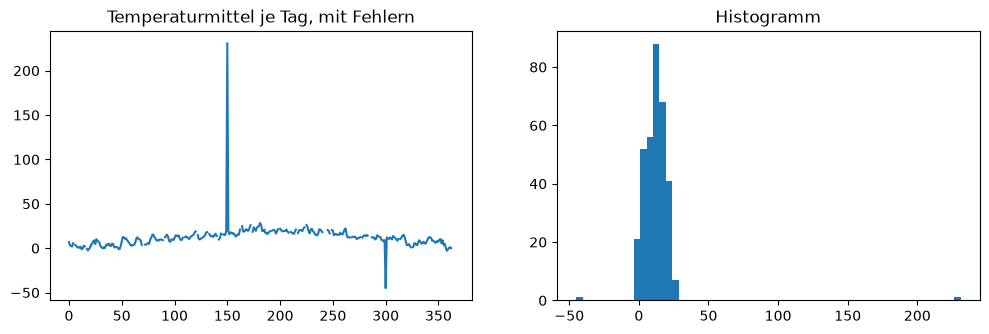

Mittelwert mit Fehlern: 12.21  ohne Fehler: 11.75


In [4]:
fehlerhaft = kaputt.copy()
fehlerhaft.loc[150, "temp_mittel"] = 231.0     # 23.1 ohne Dezimalpunkt eingetippt
fehlerhaft.loc[300, "temp_mittel"] = -45.0     # Vorzeichen und Ziffer vertauscht

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(fehlerhaft["temp_mittel"].values); axs[0].set_title("Temperaturmittel je Tag, mit Fehlern")
axs[1].hist(fehlerhaft["temp_mittel"].dropna(), bins=60); axs[1].set_title("Histogramm")
plt.show()
print("Mittelwert mit Fehlern:", fehlerhaft["temp_mittel"].mean().round(2),
      " ohne Fehler:", kaputt["temp_mittel"].mean().round(2))

Im Plot sieht man beide Fehler sofort; im Mittelwert verstecken sie sich hinter einer halben Grad. Systematisch findet man solche Werte über den **Z-Score**, die Abweichung vom Mittelwert in Einheiten der Standardabweichung (siehe [Erwartungswert und Varianz](erwartungswert.md)). Die übliche Faustregel: Werte mit $|z| > 3$ gelten als Ausreißer. Für eine Normalverteilung liegt nur einer von 370 Werten so weit draußen.

In [5]:
spalte = fehlerhaft["temp_mittel"]
z = (spalte - spalte.mean()) / spalte.std(ddof=0)      # Z-Score von Hand; NaN bleiben NaN, scipy.stats.zscore ginge auch
ausreisser = z.abs() > 3                                # Vorsicht: "< 3" wäre die Maske der *Nicht*-Ausreißer; NaN ergibt False
print(fehlerhaft.loc[ausreisser, ["datum_roh", "temp_mittel"]])


     datum_roh  temp_mittel
150   20250531        231.0
300   20251028        -45.0


Beide eingebauten Fehler werden gefunden, und nichts sonst. Das ist nicht selbstverständlich: Der Z-Score benutzt Mittelwert und Standardabweichung, und die werden von den Ausreißern selbst verzerrt. Ein einzelner sehr großer Fehler kann die Standardabweichung so aufblähen, dass kleinere Fehler unter der Schwelle bleiben. Robuster ist die Variante mit Median und Interquartilsabstand, wie sie der Boxplot benutzt.

Was tun mit einem gefundenen Ausreißer? Nicht die Zeile löschen, denn die anderen Spalten des Tages sind in Ordnung. Stattdessen den Wert auf `NaN` setzen, damit er im nächsten Abschnitt wie ein fehlender Wert behandelt wird, und die Maske aufheben.

In [6]:
bereinigt = fehlerhaft.copy()
bereinigt["temp_mittel_ausreisser"] = ausreisser
bereinigt.loc[ausreisser, "temp_mittel"] = np.nan
print("Mittelwert nach Bereinigung:", bereinigt["temp_mittel"].mean().round(2))


Mittelwert nach Bereinigung: 11.73


## Fehlende Werte

Pandas kennt drei Antworten auf einen fehlenden Wert: ignorieren (die meisten Kennzahlen wie `mean` lassen `NaN` einfach weg), die Zeile verwerfen (`dropna`) oder einen Ersatzwert einsetzen (`fillna`, **Imputation**). Verwerfen ist ehrlich, kostet aber Daten, und zwar nicht zufällig: Wenn die Sonnenscheindauer gerade in den letzten Monaten fehlt, wirft `dropna` genau diese Monate weg. Imputation behält die Zeilen, erfindet aber Werte. Die Frage ist, welche Ersatzwerte am wenigsten schaden. Wir vergleichen die gängigen Strategien an den absichtlich gelöschten Temperaturmitteln, für die wir die Wahrheit kennen, mit dem mittleren absoluten Fehler als Zielmetrik.

In [7]:
spalte = bereinigt["temp_mittel"]
monat = bereinigt["datum_roh"] // 100 % 100                  # Monatsnummer aus JJJJMMTT

strategien = {
    "Konstante 0":            spalte.fillna(0),
    "globaler Mittelwert":    spalte.fillna(spalte.mean()),
    "globaler Median":        spalte.fillna(spalte.median()),
    "Monatsmittel":           spalte.fillna(spalte.groupby(monat).transform("mean")),
    "letzter Wert (ffill)":   spalte.ffill(),
    "lineare Interpolation":  spalte.interpolate(),
}
ergebnis = {name: (ersatz[geloescht] - wahrheit[geloescht]).abs().mean() for name, ersatz in strategien.items()}
pd.Series(ergebnis, name="MAE in °C").round(2).sort_values()

lineare Interpolation     1.28
letzter Wert (ffill)      1.60
Monatsmittel              2.90
globaler Median           6.11
globaler Mittelwert       6.23
Konstante 0              13.92
Name: MAE in °C, dtype: float64

Die Reihenfolge ist typisch für Zeitreihen: Was die Nachbarn kennt (Interpolation, letzter Wert), schlägt, was nur die Gruppe kennt (Monatsmittel), und das schlägt, was nur die Gesamtheit kennt (globaler Mittelwert oder Median). Die Konstante $0$ ist abgeschlagen und trotzdem in der Praxis häufig, weil sie die Voreinstellung mancher Werkzeuge ist. Bei anderen Daten kann die Reihenfolge anders aussehen: Für eine Spalte ohne zeitliche Ordnung ist `ffill` sinnlos, und bei schiefen Verteilungen mit Ausreißern ist der Median dem Mittelwert vorzuziehen.

Zwei Details, nach denen regelmäßig gefragt wird:

* `groupby(...).transform("mean")` berechnet je Gruppe den Mittelwert und schreibt ihn in jede Zeile der Gruppe zurück; das Ergebnis hat dieselbe Länge wie die Spalte und lässt sich direkt in `fillna` einsetzen. Ist eine Gruppe komplett leer, ist ihr Mittelwert `NaN`, und die Lücke bleibt eine Lücke. Das ist richtig so.
* Ältere Anleitungen schreiben `fillna(method="ffill")`. Das gibt es in Pandas 3 nicht mehr; die Methoden heißen `ffill()` und `bfill()`.

Und noch einmal Regel 1: Nach der Imputation weiß die Spalte nicht mehr, welche Werte echt sind. Die Maske `temp_mittel_fehlt` aus dem Anfang ist die einzige Stelle, an der diese Information überlebt.

In [8]:
bereinigt["temp_mittel"] = bereinigt["temp_mittel"].interpolate()
bereinigt["temp_mittel_imputiert"] = bereinigt["temp_mittel_fehlt"] | bereinigt["temp_mittel_ausreisser"]
print(bereinigt["temp_mittel_imputiert"].sum(), "Werte in der Spalte sind nicht gemessen, sondern eingesetzt")

32 Werte in der Spalte sind nicht gemessen, sondern eingesetzt


## Datentypen, Encoding und kategoriale Werte

Die erste Prüfung nach dem Laden ist `info()`: Steht in einer Zahlenspalte der Typ `object`, hat sich ein Text eingeschlichen, etwa ein Komma als Dezimaltrenner, ein `k.A.` oder ein Tausendertrennzeichen. Solche Spalten repariert man mit `pd.to_numeric(..., errors="coerce")`, das alles Unlesbare zu `NaN` macht, und zählt danach, wie viele Werte das betroffen hat.

Text hat außerdem ein **Encoding**. Eine Datei ist eine Folge von Bytes, und erst die Kodierung sagt, welche Bytes welches Zeichen bedeuten. Der Standard ist UTF-8; ältere Dateien aus Windows-Programmen sind oft Latin-1 oder Windows-1252 kodiert. Wer die falsche Kodierung annimmt, bekommt entweder eine Fehlermeldung oder, schlimmer, stillschweigend falsche Zeichen.

In [9]:
wort = "Düsseldorf"
utf8 = wort.encode("utf-8")
latin1 = wort.encode("latin-1")
print("UTF-8:  ", utf8, len(utf8), "Bytes")
print("Latin-1:", latin1, len(latin1), "Bytes")
print("Latin-1-Bytes als UTF-8 gelesen:", latin1.decode("utf-8", errors="replace"))
print("UTF-8-Bytes als Latin-1 gelesen:", utf8.decode("latin-1"))

UTF-8:   b'D\xc3\xbcsseldorf' 11 Bytes
Latin-1: b'D\xfcsseldorf' 10 Bytes
Latin-1-Bytes als UTF-8 gelesen: D�sseldorf
UTF-8-Bytes als Latin-1 gelesen: DÃ¼sseldorf


Das zweite Ergebnis ist das berüchtigte `DÃ¼sseldorf`, das man in vielen Datenbanken findet: Jemand hat UTF-8 als Latin-1 gelesen und das Ergebnis gespeichert. `pd.read_csv` hat dafür den Parameter `encoding`; im Zweifel hilft, die ersten Bytes der Datei mit `open(..., "rb")` anzusehen.

**Kategoriale Werte** aus Freitextfeldern kommen in vielen Schreibweisen. Der Weg ist immer derselbe: erst normalisieren (Leerzeichen entfernen, Kleinschreibung), dann die verbleibenden Varianten mit einer Übersetzungstabelle zusammenführen, und für Tippfehler die Ähnlichkeit von Strings nutzen. Die Standardbibliothek bringt dafür `difflib` mit; wer es genauer braucht, nimmt die Editierdistanz (Levenshtein-Distanz), die Anzahl der Einfüge-, Lösch- und Ersetzungsschritte zwischen zwei Strings.

In [10]:
import difflib

stadt = pd.Series(["Düsseldorf", "Duesseldorf", "düsseldorf ", "Dusseldorf", "Köln", "Koeln", "Düsseldorf", "Kln"])
normalisiert = stadt.str.strip().str.lower().str.replace("ue", "ü").str.replace("oe", "ö")
tabelle = {"dusseldorf": "düsseldorf"}                       # bekannte Varianten explizit
normalisiert = normalisiert.replace(tabelle)
bekannt = ["düsseldorf", "köln"]
def naechste(s):
    treffer = difflib.get_close_matches(s, bekannt, n=1, cutoff=0.6)
    return treffer[0] if treffer else s
ergebnis = normalisiert.map(naechste)
print(pd.DataFrame({"roh": stadt, "normalisiert": normalisiert, "zugeordnet": ergebnis}))
print("\nAusprägungen vorher:", stadt.nunique(), " nachher:", ergebnis.nunique())

           roh normalisiert  zugeordnet
0   Düsseldorf   düsseldorf  düsseldorf
1  Duesseldorf   düsseldorf  düsseldorf
2  düsseldorf    düsseldorf  düsseldorf
3   Dusseldorf   düsseldorf  düsseldorf
4         Köln         köln        köln
5        Koeln         köln        köln
6   Düsseldorf   düsseldorf  düsseldorf
7          Kln          kln        köln

Ausprägungen vorher: 7  nachher: 2


Aus sieben Schreibweisen werden zwei Städte. Auch das ist eine Verfälschung: Die Zuordnung `Kln` zu `köln` ist eine Vermutung, und bei einer echten Stadt namens "Kln" wäre sie falsch. Deshalb gehört die Tabelle der Zuordnungen ins Protokoll.

Wie man kategoriale Werte anschließend in Zahlen übersetzt (Ordinal- und One-Hot-Encoding), steht in der Tabelle zum Skalenniveau im Kapitel [Deskriptive Statistik](deskriptive-statistik.md).

## Reguläre Ausdrücke

Sobald eine Spalte Text enthält, aus dem man etwas herausziehen will (den Titel aus einem Namen, die Domain aus einer URL, die Postleitzahl aus einer Adresse), braucht man **reguläre Ausdrücke**. Der Ruf, kryptische Zeichenketten zu sein, kommt vom Aufschreiben, nicht von der Sache. Ein regulärer Ausdruck ist eine kompakte Beschreibung eines endlichen Automaten, den Sie aus der Vorlesung über formale Sprachen kennen: Er läuft von links nach rechts über den String und entscheidet an jeder Stelle, ob das Zeichen passt. Zwei Regeln machen den Umgang erträglich:

1. Reguläre Ausdrücke **mehrzeilig mit Kommentaren** schreiben. Python erlaubt das mit dem Flag `re.VERBOSE`; Leerzeichen und Zeilenumbrüche im Muster werden dann ignoriert, und hinter `#` steht ein Kommentar.
2. Was man herausziehen will, in **Gruppen** klammern. `re.search` liefert die Gruppen, Pandas `str.extract` macht daraus Spalten.

In [11]:
import re

urls = pd.Series(["https://www.hhu.de/studium", "http://opendata.dwd.de/climate_environment/CDC/",
                  "https://voelkel.pages.cs.uni-duesseldorf.de/ds-skript/", "mailto:info@example.org"])
muster = re.compile(r"""
    ^https?://          # Schema: http oder https, dann ://
    ([^/]+)             # Gruppe 1: alles bis zum nächsten Schrägstrich, das ist der Host
    (/.*)?$             # Gruppe 2 (optional): der Pfad ab dem Schrägstrich
""", re.VERBOSE)
print(urls.str.extract(muster))

                                     0                          1
0                           www.hhu.de                   /studium
1                      opendata.dwd.de  /climate_environment/CDC/
2  voelkel.pages.cs.uni-duesseldorf.de                /ds-skript/
3                                  NaN                        NaN


Die letzte Zeile ist `NaN`, weil `mailto:` nicht auf das Muster passt. Das ist erwünscht: Ein regulärer Ausdruck sagt nicht nur, *was* er findet, sondern auch, *dass* etwas nicht dem erwarteten Format entspricht. Die Zahl der `NaN` nach einem `extract` ist deshalb eine Prüfgröße für die Datenqualität.

Die häufigste Falle ist die **Gier** der Wiederholungsoperatoren. `.*` nimmt so viele Zeichen wie möglich und gibt nur so viel zurück, wie nötig ist, damit der Rest des Musters noch passt. Beim Automaten heißt das: Er läuft bis zum Ende und geht dann rückwärts. Die "faule" Variante `.*?` nimmt so wenig wie möglich.

In [12]:
html = '<a href="eins.html">Eins</a> und <a href="zwei.html">Zwei</a>'
print("gierig:", re.findall(r'<a href="(.*)">', html))     # nimmt bis zum letzten ">
print("faul:  ", re.findall(r'<a href="(.*?)">', html))    # nimmt bis zum nächsten ">

gierig: ['eins.html">Eins</a> und <a href="zwei.html']
faul:   ['eins.html', 'zwei.html']


Zwei Konstruktionen lohnen sich, weil sie Probleme lösen, an denen man sonst lange bastelt.

Der **negative Lookahead** `(?!…)` prüft, dass an dieser Stelle etwas *nicht* steht, ohne dabei Zeichen zu verbrauchen. So passt `(?!23)\d\d` auf jede zweistellige Zahl außer `23`. Das Gegenstück `(?=…)` verlangt, dass etwas folgt.

Eine **Rückwärtsreferenz** `\1` steht für das, was Gruppe 1 gefunden hat, und verlangt, dass es noch einmal genauso dasteht. Damit findet man doppelte Wörter — der klassische Tippfehler, den kein Rechtschreibprüfer der frühen Textverarbeitung erwischt hat.

In [13]:
print(re.findall(r"(?!23)\d\d", "22 23 24"))   # 23 fehlt, 22 und 24 sind dabei

doppelt = re.compile(r"\b(\w+)\s+\1\b")
print(doppelt.search("Sie ist die die beste")[1])     # 'die'
print(doppelt.sub(r"\1", "Sie ist die die beste"))    # einmal reicht

['22', '24']
die
Sie ist die beste


Gruppen sind auch der Grund, warum ein Muster mehr zurückgeben kann als „passt / passt nicht“. Das Muster

```python
r"^<([a-z]+?)>(.*)</([a-z]+?)>$"
```

zerlegt `"<p>html code</p>"` in die drei Gruppen `"p"`, `"html code"` und `"p"`. Es zeigt aber auch gleich die Grenze: Auf `'<a href="url">text</a>'` passt es nicht, weil im öffnenden Tag ein Attribut steht. Man kann das Muster erweitern, und dann kommt das nächste Gegenbeispiel. Die Lehre daraus ist bekannt und gilt unverändert: **HTML zerlegt man nicht mit regulären Ausdrücken**, sondern mit einem Parser — HTML ist keine reguläre Sprache, und kein endlicher Automat kann verschachtelte Tags zählen. Für ein einzelnes, bekanntes Feld in einer Textspalte sind reguläre Ausdrücke dagegen genau das richtige Werkzeug.

Mehr als diese Bausteine braucht man selten. Die folgende Tabelle ist die Kurzfassung, von oben (schwach bindend) nach unten (stark bindend) gelesen:

| Baustein | Schreibweise | Beispiel | passt auf |
|---|---|---|---|
| Alternative | `A\|B` | `a\|b` | `a` oder `b` |
| Verkettung | `AB` | `ab` | `ab` |
| Wiederholung, beliebig oft | `A*` | `a*` | nichts, `a`, `aa`, … |
| Wiederholung, mindestens einmal | `A+` | `a+` | `a`, `aa`, … |
| Wiederholung, optional | `A?` | `a?` | nichts oder `a` |
| Wiederholung, gezählt | `A{n,m}` | `a{2,4}` | `aa`, `aaa`, `aaaa` |
| Gruppe | `(A)` | `(ab\|c)` | `ab` oder `c`, als Gruppe merkbar |
| beliebiges Zeichen | `.` | `ab.d` | `abcd`, `ab7d`, … |
| Zeichenklasse | `[…]` | `[abc]`, `[a-z]` | eines der genannten Zeichen |
| negierte Zeichenklasse | `[^…]` | `[^def]` | alles außer `d`, `e`, `f` |
| Anker | `^`, `$` | `abc$` | `abc` am Zeilenende |

Zeichen mit Sonderbedeutung (`.`, `*`, `+`, `?`, `(`, `)`, `[`, `]`, `|`, `^`, `$`, `\`) schreibt man mit vorangestelltem Backslash, wenn man sie wörtlich meint: `\.` passt auf einen Punkt. Deshalb schreibt man Muster in Python immer als Raw-String `r"…"` — sonst müsste man jeden Backslash verdoppeln.

Wer regelmäßig damit arbeitet, sollte einmal das Buch von Friedl lesen {cite}`friedl2006`, das erklärt, wie die Automaten wirklich laufen und warum manche Muster langsam sind.

:::{admonition} Beispielaufgabe: Anreden im Titanic-Datensatz
:class: tip
Die Spalte `Name` der Titanic-Passagierliste hat die Form `Nachname, Anrede. Vornamen`, etwa `Braund, Mr. Owen Harris`. Extrahieren Sie die Anrede in eine neue Spalte, zählen Sie die Ausprägungen, fassen Sie seltene und gleichbedeutende Anreden zusammen und berechnen Sie die Überlebensrate je Anrede. Was sagt das Ergebnis über die Rettungsreihenfolge?
:::

In [14]:
titanic = pd.read_csv("titanic.csv")
titanic["Anrede"] = titanic["Name"].str.extract(r",\s*([^.]+)\.")   # nach dem Komma bis zum ersten Punkt
print(titanic["Anrede"].value_counts())

Anrede
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [15]:
zusammen = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
            "Dr": "Rang", "Rev": "Rang", "Col": "Rang", "Major": "Rang", "Capt": "Rang",
            "Sir": "Adel", "Lady": "Adel", "the Countess": "Adel", "Don": "Adel", "Jonkheer": "Adel"}
titanic["Anrede"] = titanic["Anrede"].replace(zusammen)
titanic.groupby("Anrede")["Survived"].agg(["mean", "size"]).sort_values("mean", ascending=False)

,mean,size
Anrede,,
Mrs,0.793651,126
Miss,0.702703,185
Adel,0.600000,5
Master,0.575000,40
Rang,0.277778,18
Mr,0.156673,517


:::{admonition} Lösung
:class: dropdown
Die beiden ausgeblendeten Zellen oben enthalten den Code. Das Muster `,\s*([^.]+)\.` liest nach dem Komma und optionalen Leerzeichen alle Zeichen bis zum ersten Punkt in eine Gruppe. Es gibt siebzehn Anreden, die meisten selten; `Mlle` und `Ms` sind Varianten von `Miss`, `Mme` von `Mrs`, die Berufs- und Adelstitel fasst man in zwei Gruppen zusammen. Die Überlebensraten sind dann: `Mrs` und `Miss` um 70 bis 80 Prozent, `Master` (Jungen) über 50 Prozent, `Mr` unter 20 Prozent. Das ist die Regel "Frauen und Kinder zuerst", abgelesen aus einem Textfeld. Die Anrede ist damit ein besseres Merkmal für Vorhersagen als das Geschlecht allein, weil sie zusätzlich das Alter der Jungen kodiert; so etwas nennt man *Feature Engineering*.
:::

Reguläre Ausdrücke lernt man nicht durch Lesen. Zwei Seiten helfen beim Üben: [regexone.com](https://regexone.com) führt in fünfzehn kleinen Aufgaben durch alle Bausteine, und der [Regex-Visualizer](https://27t.github.io/regex-visualizer/) zeichnet zu einem Muster den endlichen Automaten — für `a(ffe|de)+` sieht man dort unmittelbar, wo die Schleife sitzt, die das `+` erzeugt.

## Datum, Uhrzeit und Zeitzonen

Datumsangaben sind Text in einem von Dutzenden Formaten: `20250115`, `15.01.2025`, `01/15/2025`, `2025-01-15T14:30:00+01:00`, oder eine Zahl von Sekunden seit dem 1. Januar 1970 (der *Unix-Zeitstempel*). Pandas liest die meisten davon mit `to_datetime`. Man sollte das Format aber angeben, statt es raten zu lassen: Beim Datum `01/02/2025` ist Raten Glückssache, und Raten ist außerdem langsam. Und das Rohdatum behält man als Spalte, bis man sicher ist, dass die Umwandlung stimmt.

In [16]:
bereinigt["datum"] = pd.to_datetime(bereinigt["datum_roh"], format="%Y%m%d")
print(bereinigt[["datum_roh", "datum"]].head(3))
print("\nTyp der neuen Spalte:", bereinigt["datum"].dtype)

   datum_roh      datum
0   20250101 2025-01-01
1   20250102 2025-01-02
2   20250103 2025-01-03

Typ der neuen Spalte: datetime64[us]


Mit einem echten Datumstyp werden die nützlichen Fragen zu Einzeilern: Wochentag, Monat, Abstand zwischen zwei Tagen, oder das Zusammenfassen auf Monate mit `resample`. Dafür setzen wir das Datum als Index.

In [17]:
w = bereinigt.set_index("datum")
print("Wochentag des ersten Eintrags:", w.index[0].day_name())
print("Tage zwischen erstem und letztem Eintrag:", (w.index[-1] - w.index[0]).days)
monatlich = w[["temp_mittel", "niederschlag"]].resample("MS").agg({"temp_mittel": "mean", "niederschlag": "sum"})
monatlich.round(1).head(6)

Wochentag des ersten Eintrags: Wednesday
Tage zwischen erstem und letztem Eintrag: 364


,temp_mittel,niederschlag
datum,,
2025-01-01,3.2,103.6
2025-02-01,4.3,18.6
2025-03-01,8.0,6.2
2025-04-01,12.1,71.0
2025-05-01,14.5,23.8
2025-06-01,19.6,52.4


**Zeitzonen** sind die Stelle, an der die meisten Fehler passieren. Ein Zeitstempel ohne Zeitzone ist mehrdeutig: `2025-03-30 02:30` hat es in Deutschland nie gegeben, weil in dieser Nacht die Uhr von 2:00 auf 3:00 gesprungen ist, und `2025-10-26 02:30` gab es zweimal. Pandas unterscheidet deshalb *naive* Zeitstempel (ohne Zeitzone) und *bewusste* (mit). `tz_localize` sagt, in welcher Zeitzone ein naiver Zeitstempel gemeint war; `tz_convert` rechnet einen bewussten in eine andere Zeitzone um. Die beiden zu verwechseln verschiebt alle Zeiten um eine oder zwei Stunden, und das fällt erst auf, wenn der Sonnenaufgang um 6 Uhr statt um 7 Uhr in den Daten steht.

In [18]:
zeiten = pd.to_datetime(["2025-01-15 12:00", "2025-07-15 12:00"])   # naiv: keine Zeitzone
lokal = zeiten.tz_localize("Europe/Berlin")                           # so waren sie gemeint
print("lokal:", list(lokal))
print("UTC:  ", list(lokal.tz_convert("UTC")))                        # im Winter +1, im Sommer +2 Stunden Unterschied
print("Unix-Zeitstempel:", list((lokal - pd.Timestamp("1970-01-01", tz="UTC")) // pd.Timedelta("1s")))  # Sekunden seit 1970, zeitzonenfrei
try:
    pd.Timestamp("2025-03-30 02:30").tz_localize("Europe/Berlin")
except Exception as fehler:
    print("Fehler:", type(fehler).__name__, "-", fehler)

lokal: [Timestamp('2025-01-15 12:00:00+0100', tz='Europe/Berlin'), Timestamp('2025-07-15 12:00:00+0200', tz='Europe/Berlin')]
UTC:   [Timestamp('2025-01-15 11:00:00+0000', tz='UTC'), Timestamp('2025-07-15 10:00:00+0000', tz='UTC')]
Unix-Zeitstempel: [1736938800, 1752573600]
Fehler: ValueError - 2025-03-30 02:30:00 is a nonexistent time due to daylight savings time. Try using the 'nonexistent' argument.


Die Zeitzonenregeln samt aller Sommerzeit-Umstellungen der Vergangenheit stehen in der *tz database* (auch IANA-Zeitzonendatenbank), die Python mit dem Modul `zoneinfo` mitbringt; die Namen wie `Europe/Berlin` stammen von dort. Wer Zeitstempel speichert, speichert sie in UTC oder als Unix-Zeitstempel und rechnet erst bei der Anzeige in die Ortszeit um.

## Zusammenfassung

Der bereinigte DataFrame trägt jetzt neben den Messwerten drei Spalten, die nur das Protokoll sind: welche Werte gefehlt haben, welche als Ausreißer erkannt wurden und welche deshalb eingesetzt sind. Wer später ein Modell darauf trainiert, kann diese Zeilen ausschließen oder gewichten, und wer die Analyse liest, sieht, was Messung ist und was Vermutung.

In [19]:
bereinigt[["datum", "temp_mittel", "temp_mittel_fehlt", "temp_mittel_ausreisser", "temp_mittel_imputiert"]].iloc[148:153]

,datum,temp_mittel,temp_mittel_fehlt,temp_mittel_ausreisser,temp_mittel_imputiert
148,2025-05-29,14.7,False,False,False
149,2025-05-30,19.6,False,False,False
150,2025-05-31,19.2,False,True,True
151,2025-06-01,18.8,False,False,False
152,2025-06-02,15.7,False,False,False


:::{admonition} Take-Home-Message
Putzen verfälscht immer. Erlaubt ist es, wenn jede Änderung im Code steht, eine Maske festhält, welche Werte betroffen sind, und die Wahl der Methode an einer Zielmetrik gemessen wurde. Vor dem Rechnen `info()` und ein Plot, nach dem Putzen noch ein Plot.
:::

Wie es weitergeht: Mit sauberen Tabellen können wir Zusammenhänge zwischen Spalten untersuchen. Das nächste Kapitel führt dafür Kovarianz und Korrelation ein.